# **1. Сформулировать постановку задачу, которую хочется решать в рамках курса.**

**Бизнес-задача:**
Мы с командой профкома разрабатываем сервис электронной подачи заявлений на материальную поддержку в университете (обязательна к наличию в ОО, 273 ФЗ ст. 34). Алгоритм следующий: студент заполняет электронное заявление, прикладывая документы в формате PDF (в т.ч. это могут быть документы с QR-кодами под видом документов с Госуслуг).

**Проблема:**
Текущая архитектура сервиса принимает файлы от внешних пользователей без глубокой ИБ-валидации. Это создает следующие критические уязвимости:
1. Вредоносный контент в PDF: Риск загрузки файлов со встроенными эксплойтами, исполняемым JavaScript-кодом, скрытыми вложениями или авто-действиями при открытии.
2. Фишинг через QR-коды: Риск размещения на документах поддельных QR-кодов, ведущих на фишинговые и вредоносные ресурсы.
3. Человеческий фактор: Сотрудники профкома обрабатывают поток заявлений вручную. Они не способны визуально определить скрытые киберугрозы, а штатное антивирусное ПО не учитывает специфику университетского документооборота.

**Для кого эта проблема критична:**

* Служба УИБ университета – отвечает за защиту инфраструктуры и ПДн
*   Студенты – утечка ПДн студентов, ранее подавших заявления через этот сервис
*   Университет – репутационные и юридические риски

**Актуальность автоматизации:**
Обработка заявлений вручную занимает много времени, в том числе из рабочих часов сотрудника, которые он мог бы потратить на выполнение других задач; подвержена ошибкам, так как вредоносные файлы не всегда могут быть распознаны сотрудником. Также проверка заявлений вручную не масштабируется при росте числа заявлений. Штатный антивирус не учитывает специфику университетского документооборота, поэтому требуется дополнительный слой поведенческой и контентной проверки.

**Бизнес-эффект:**
Снижение риска заражения и утечки ПДн, разгрузка сотрудников профкома, сохранение доверия студентов к сервису.

**Ограничения:**
Пропуск вредоносного файла критичен, но массовые ложные блокировки легитимных документов недопустимы, так как заблокируют подачу заявлений. Решение должно работать быстро, быть объяснимым для сотрудника ИБ и не нарушать приватность персональных данных.



**ML-задача:**

Задача машинного обучения формулируется как бинарная классификация PDF-файлов на безопасные и вредоносные или подозрительные.

**Объект классификации:**
Один PDF-файл, приложенный к заявлению на материальную поддержку.

Целевая переменная:

* (y=0) - безопасный файл;

* (y=1) - вредоносный или подозрительный файл.

Положительным классом считается класс вредоносных файлов, поскольку их ошибочная классификация как безопасных представляет существенный риск для информационной безопасности университета.
* Входные данные модели — вектор признаков, извлечённых из PDF-файла. В качестве признаков предполагается использовать:
* Общие характеристики: размер файла, версия PDF, соответствие расширения фактическому формату;
* Структурные характеристики: количество объектов, наличие встроенных файлов и подозрительных элементов;
* Признаки потенциально опасного поведения: наличие JavaScript, автоматических действий при открытии документа и других активных конструкций;
* Характеристики содержимого: наличие QR-кодов и домены, на которые ведут содержащиеся в них ссылки;
* Дополнительные статистические признаки, например энтропию отдельных областей файла.

Перед передачей файла модели сервис проверяет его формат и размер. В рамках проекта рассматриваются только PDF-файлы размером не более 50 МБ. Файлы других форматов и превышающие установленный лимит отклоняются на этапе предварительной валидации.

На выходе модель формирует оценку вероятности принадлежности файла к вредоносному классу (от 0 до 1). Итоговая классификация определяется порогом, выбранным на валидационной выборке с учётом требований информационной безопасности.



**Набор данных:**


Для учебного исследования возьмем открытый датасет с платформы Kaggle, загружаемый с помощью библиотеки KaggleHub. Выбор такого источника обусловлен отсутствием собственных размеченных данных на этапе разработки проекта.

Открытый набор данных позволяет изучить структуру исходных данных, выполнить разведочный анализ, проверить качество признаков и подготовить основу для построения модели классификации.

При анализе набора данных необходимо учитывать его фактические характеристики: количество объектов, состав признаков, распределение целевых классов и наличие пропусков. Эти параметры определяются непосредственно по загруженному датасету и не должны подменяться предположительными значениями.

Выбранный датасет используется как исследовательская основа для разработки и первичной оценки прототипа. Возможность практического применения модели должна быть дополнительно проверена после появления данных, соответствующих условиям целевого сервиса.


# **2. Выбор метрик оценки качества модели**

**Основные метрики:**

Recall показывает, какую часть всех вредоносных файлов модель смогла обнаружить. Пропуск опасного файла может создать угрозу для безопасности университета.

Precision (точность положительных предсказаний) показывает, сколько файлов из всех документов, которые модель посчитала вредоносными, действительно относятся к этому классу. Благодоря этой метрике безопасные документы не будут отправляться на проверку слишком часто. Если модель будет часто ошибочно помечать безопасные документы как вредоносные, сотрудникам придется проверять много файлов без необходимости.

В качестве предварительных целей для модели можно использовать следующие значения:

* Recall ≥ 0,98 - модель должна обнаруживать не менее 98% вредоносных файлов.

* Precision ≥ 0,85 - среди файлов, которые модель определила как вредоносные, не менее 85% должны действительно относиться к этому классу.

Эти значения являются целевыми показателями, которые необходимо проверить в ходе эксперимента.

**Ограниченя оценки**

Для более объективной оценки данные необходимо разделить на обучающую и тестовую выборки. Модель обучается на первой части, а затем проверяется на данных, которые она ранее не видела. Это позволит лучше понять, насколько хорошо она справляется с классификацией новых файлов.

# **3. Разведочный анализ данных (EDA)**

Так как проект находится в разработке, реальных данных университетского сервиса, на которых можно было бы обучить и проверить модель, пока нет. Поэтому для учебного исследования используется открытый датасет pdf-samples-clean-and-malicious, загруженный с помощью библиотеки KaggleHub.

Датасет содержит информацию о PDF-файлах двух классов: безопасных и вредоносных. Файлы загружаются из clean.csv и malware.csv.

**Структура данных**



На первом этапе устанавливаются необходимые библиотеки, загружается датасет и подключаются инструменты для работы с таблицами и визуализации данных.

In [1]:
import os
import re
import warnings

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


!pip install kagglehub -q
import kagglehub
import pandas as pd
path = kagglehub.dataset_download("deva2k2r/pdf-samples-clean-and-malicious")
print(path)

benign = pd.read_csv(f"{path}/clean.csv")
malicious = pd.read_csv(f"{path}/malware.csv")

100%|██████████| 874M/874M [00:11<00:00, 80.0MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/deva2k2r/pdf-samples-clean-and-malicious/versions/2


После загрузки двум наборам данных присваиваются метки классов, затем они объединяются в одну таблицу. Далее проверяются размер датасета, типы данных и основные статистические характеристики признаков.

Это позволяет понять, сколько объектов участвует в исследовании и какие данные доступны для дальнейшего анализа.

In [2]:
benign = pd.read_csv(f"{path}/clean.csv")
malicious = pd.read_csv(f"{path}/malware.csv")

benign["label"] = 0
malicious["label"] = 1

df = pd.concat([benign, malicious], ignore_index=True)

print("Размер датасета:", df.shape)
df.head()
df.info()
df.describe()

Размер датасета: (20210, 30)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20210 entries, 0 to 20209
Data columns (total 30 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   /JS             20210 non-null  int64  
 1   /JavaScript     20210 non-null  int64  
 2   startxref       20210 non-null  int64  
 3   xref            20210 non-null  int64  
 4   obj             20210 non-null  int64  
 5   endobj          20210 non-null  int64  
 6   stream          20210 non-null  int64  
 7   /OpenAction     20210 non-null  int64  
 8   /XFA            20210 non-null  int64  
 9   Filesize_kb     20210 non-null  float64
 10  MetadataStream  20210 non-null  int64  
 11  Optimized       20210 non-null  int64  
 12  Pages           20210 non-null  int64  
 13  /Size           20210 non-null  int64  
 14  %EOF            20210 non-null  int64  
 15  /Producer       20210 non-null  int64  
 16  /ProcSet        20210 non-null  int64  
 17  /I

,/JS,/JavaScript,startxref,xref,obj,endobj,stream,/OpenAction,/XFA,Filesize_kb,...,/CreationDate,/Info,/Font,/XML,/Rect,Referencing,Headerlength,small_content,Malicecontent,label
count,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,...,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000,20210.000000
mean,0.671945,0.821573,1.441860,1.219149,47.449777,47.423355,15.913953,0.449827,0.052251,57.994164,...,0.595745,0.861207,16.188619,0.472390,3.635626,47.405393,30.571153,0.540228,0.512370,0.549283
std,3.400705,3.466690,0.992579,0.939571,131.988828,131.995736,38.829991,0.514023,0.226724,247.534929,...,0.786006,1.243036,35.482210,1.383278,47.997806,131.977852,15.592852,0.498391,0.499859,0.497578
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.023438,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,1.000000,9.000000,9.000000,2.000000,0.000000,0.000000,9.290039,...,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,0.000000,0.000000
50%,1.000000,1.000000,1.000000,1.000000,11.000000,11.000000,3.000000,0.000000,0.000000,16.383789,...,1.000000,1.000000,1.000000,0.000000,0.000000,11.000000,44.000000,1.000000,1.000000,1.000000
75%,1.000000,1.000000,2.000000,2.000000,39.000000,39.000000,14.000000,1.000000,0.000000,74.032471,...,1.000000,1.000000,19.000000,1.000000,1.000000,39.000000,44.000000,1.000000,1.000000,1.000000
max,404.000000,404.000000,68.000000,46.000000,7076.000000,7076.000000,2063.000000,12.000000,5.000000,23258.375000,...,35.000000,67.000000,1601.000000,148.000000,5648.000000,7076.000000,97.000000,1.000000,1.000000,1.000000


На следующем этапе проверяется наличие пропущенных значений и повторяющихся строк. Это необходимо, чтобы выявить возможные проблемы с качеством данных до обучения модели.

Результаты проверки помогут определить, требуется ли дополнительная обработка данных. Так как дубликаты и пропуски не обнаружены, то дополнительная обработка данных не требуется

In [3]:
df.isna().sum().sort_values(ascending=False).head(10)
df.duplicated().sum()

np.int64(0)

**Анализ распределения классов**

Для оценки соотношения безопасных и вредоносных файлов рассчитывается доля каждого класса и строится столбчатая диаграмма.

Это важно, поскольку количество объектов разных классов может существенно отличаться. Если один класс преобладает, это необходимо учитывать при обучении модели и выборе метрик оценки качества.

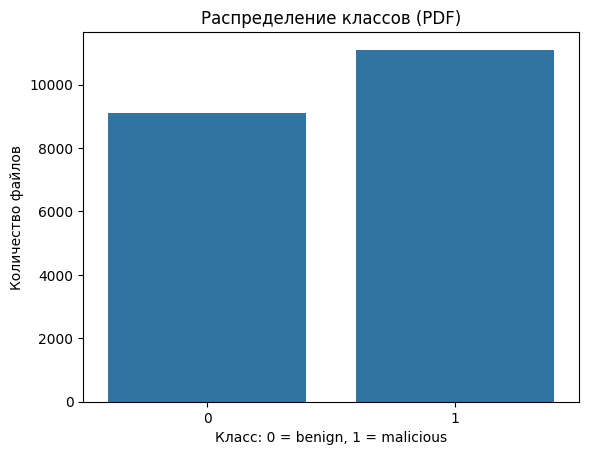

In [4]:
df["label"].value_counts(normalize=True)

#Баланс классов
sns.countplot(data=df, x="label")
plt.title("Распределение классов (PDF)")
plt.xlabel("Класс: 0 = benign, 1 = malicious")
plt.ylabel("Количество файлов")
plt.show()

**Анализ размера PDF-файлов**

Далее анализируется распределение размера файлов в зависимости от класса. Для этого строится гистограмма с логарифмической шкалой, позволяющая лучше рассмотреть различия при большом разбросе размеров.

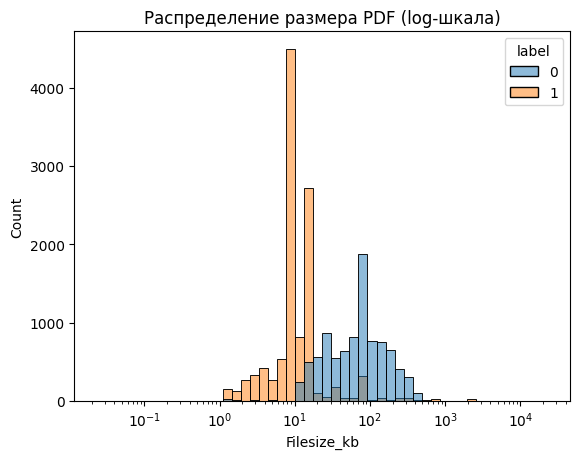

In [5]:
#Размер файла
sns.histplot(data=df, x="Filesize_kb", hue="label", log_scale=True, bins=50)
plt.title("Распределение размера PDF (log-шкала)")
plt.show()


**Анализ отдельных признаков PDF**

Для дальнейшего исследования рассматриваются признаки, связанные со структурой PDF-документов: /JavaScript, /OpenAction, /XFA, /JS, /EmbeddedFile и /Launch.

Сначала проверяется, какие из перечисленных признаков присутствуют в датасете. Затем для каждого доступного признака строится график, позволяющий сравнить его распространенность среди безопасных и вредоносных файлов.

С помощью этих графиков можно определить, встречаются ли отдельные структурные признаки чаще в одном из классов.

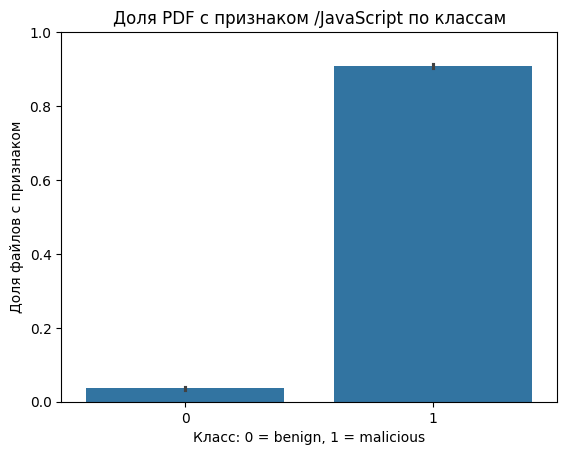

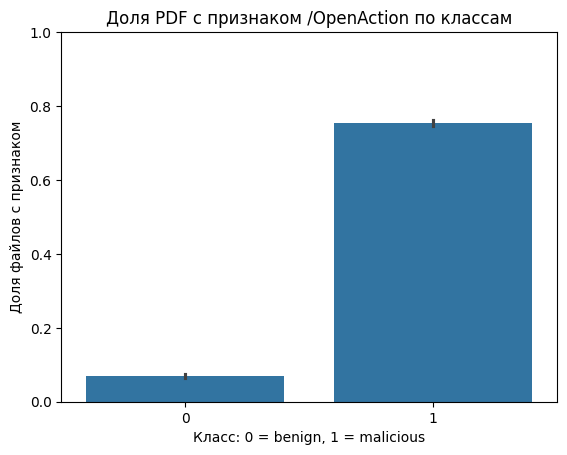

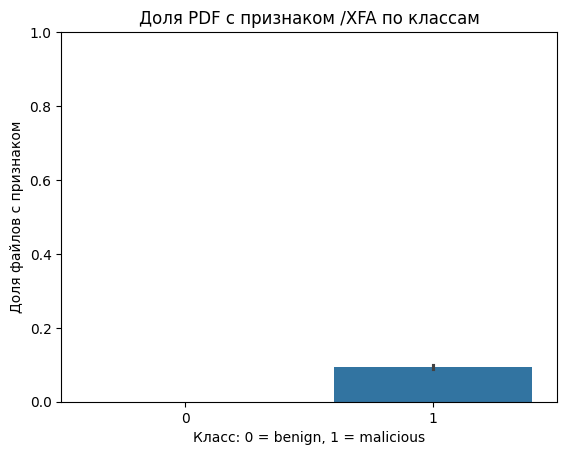

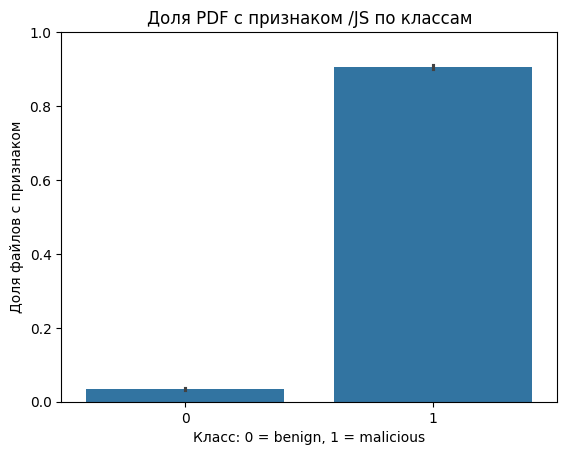

In [12]:
key_features = [
    "/JavaScript",
    "/OpenAction",
    "/XFA",
    "/JS",
    "/EmbeddedFile",
    "/Launch"
]

existing = [col for col in key_features if col in df.columns]

for col in existing:
    # Проверяем наличие признака, а не его количество
    feature_present = (df[col] > 0).astype(int)

    plot_data = pd.DataFrame({
        "label": df["label"],
        "present": feature_present
    })

    sns.barplot(data=plot_data, x="label", y="present")

    plt.title(f"Доля PDF с признаком {col} по классам")
    plt.xlabel("Класс: 0 = benign, 1 = malicious")
    plt.ylabel("Доля файлов с признаком")
    plt.ylim(0, 1)
    plt.show()

**Визуализация пропущенных значений**

Эта визуализация помогает оценить, насколько равномерно заполнены данные и есть ли признаки с большим количеством пропущенных значений.

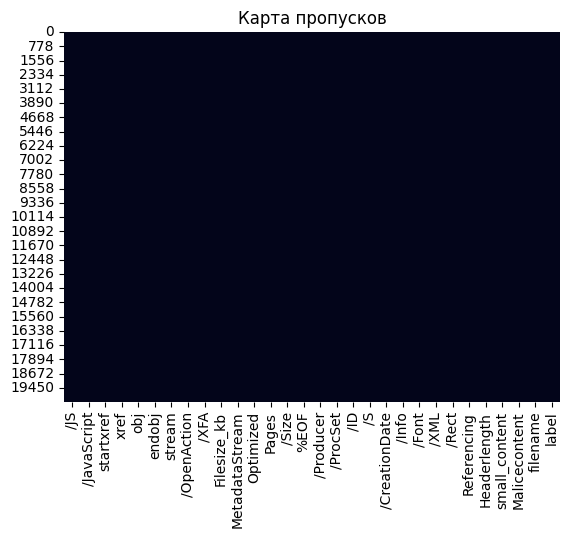

In [7]:
#Карта пропусков
sns.heatmap(df.isna(), cbar=False)
plt.title("Карта пропусков")
plt.show()

**Анализ корреляций между числовыми признаками**

Для предварительного анализа связей между числовыми признаками строится корреляционная матрица. Она позволяет выявить признаки, которые могут содержать похожую информацию, и определить, какие взаимосвязи стоит изучить подробнее. Результаты используются как вспомогательная информация при подготовке данных к обучению модели.

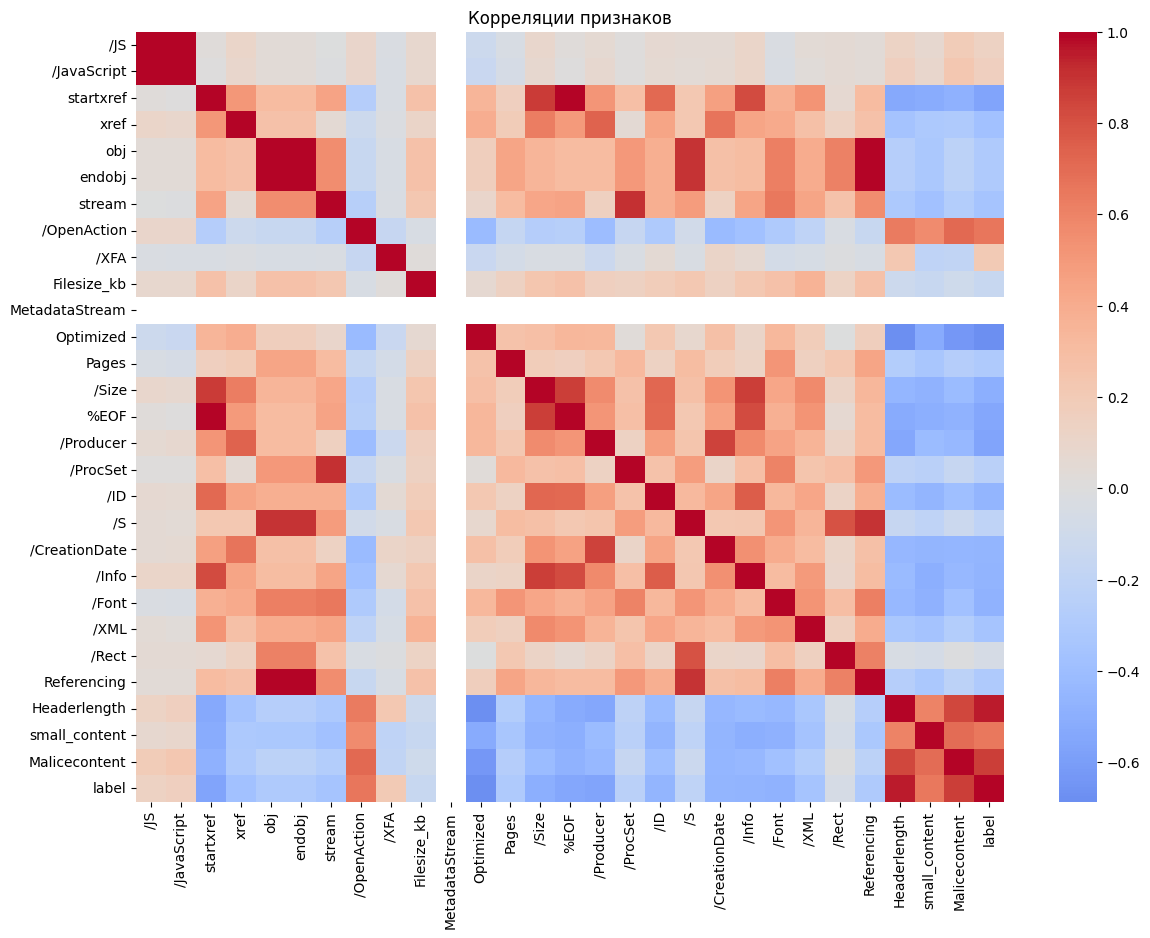

In [8]:
#Корреляции
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Корреляции признаков")
plt.show()

**Анализ связи энтропии и размера файла**

Если в датасете присутствует признак Entropy, дополнительно строится диаграмма рассеяния, показывающая связь между энтропией и размером PDF-файла. Цвет точек отражает класс документа.

Этот график позволяет визуально оценить, различаются ли безопасные и вредоносные файлы по сочетанию двух характеристик.

In [11]:
#Энтропия/размер
if "Entropy" in df.columns:
    sns.scatterplot(data=df, x="Entropy", y="Filesize_kb", hue="label", alpha=0.5)
    plt.title("Энтропия vs размер файла")
    plt.show()

**Выводы по результатам EDA**

В ходе EDA был изучен датасет из 20 210 PDF-файлов и 30 столбцов. Пропущенных значений и полных дубликатов не обнаружено, выраженного дисбаланса классов по графику не наблюдается.

Анализ показал, что вредоносные файлы в этом датасете чаще имеют меньший размер, чем безопасные. Также были изучены признаки /JavaScript, /JS, /OpenAction и /XFA, которые могут помочь выявить различия между классами. Корреляционная матрица позволила оценить связи между числовыми признаками. Признак MetadataStream не изменяется и поэтому не помогает различать классы.

Таким образом, EDA помог изучить данные и определить особенности признаков, которые нужно учитывать при подготовке модели.